Plan projektu: Syntezator mowy metodą syntezy formantowej (LPC)

Celem projektu jest stworzenie niskopoziomowego syntezatora mowy
opartego na syntezie formantowej, z pełnym łańcuchem przetwarzania:
analiza sygnału → ekstrakcja parametrów LPC → detekcja dźwięczności →
synteza mowy. Wszystkie kluczowe algorytmy (resampling, LPC,
autokorelacja) muszą zostać zaimplementowane samodzielnie.

1.  Decymacja sygnału (własna implementacja)

-   Przepróbkowanie sygnału z filtracją antyaliasingową.
-   Decymacja właściwa.

2.  Usunięcie składowej stałej

-   Odjęcie wartości średniej sygnału.

3.  Normalizacja sygnału

-   Normalizacja RMS względem nagrania wzorcowego.

4.  Ramkowanie sygnału

-   Ramki 20–30 ms, opcjonalne nakładanie i okienkowanie.

5.  Obwiednia widmowa – LPC-10 (własna implementacja)

-   Obliczenie 10 współczynników LPC, gain oraz pobudzenia.

6.  Klasyfikacja ramek (voiced/unvoiced)

-   Wykrywanie f0 poprzez autokorelację.
-   Oznaczanie: 1 – dźwięczna, 0 – bezdźwięczna.

Macierz parametrów: - 12 wierszy (10 LPC + gain + voiced/unvoiced) -
kolumny = kolejne ramki.

7.  Synteza mowy

-   Generacja pobudzenia (impulsy lub szum).
-   Filtracja przez filtr LPC.
-   Sklejanie ramek i odtwarzanie sygnału.

Na końcu porównanie oryginalnego i zsyntezowanego sygnału.

In [ ]:
# używane biblioteki:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, filtfilt
import scipy.signal as signal
from math import floor, ceil
import soundfile as sf
from IPython.display import Audio, display
from fractions import Fraction

In [ ]:
# I/O

def read_wav(path):

    x, fs = sf.read(path, dtype='float32')
    if x.ndim > 1:
        x = np.mean(x, axis=1)
    return fs, x

def write_wav(path, fs, x):
    sf.write(path, x.astype('float32'), fs)

In [ ]:
def sinc_kernel(cutoff, num_taps): # funkcja tworząca filtr FIR z oknem hamminga

    M = num_taps - 1

    n = np.arange(0, num_taps) - M/2.0 # symetryczny rozkład próbek wokół zera

    # np.sinc(x) = sin(pi*x)/(pi*x)
    # skalujemy argument tak, by odpowiadał zadanej częstotliwości odcięcia.
    # 2*cutoff dlatego, że np.sinc interpretuje argument w jednostkach normalizowanych do pi.
    h = np.sinc(2 * cutoff * n)

    h *= np.hamming(num_taps) # nakładamy okno Hamming'a aby zmniejszyć przebiegi boczne

    h /= np.sum(h) + 1e-16 # normalizacja sumy wsp do 1

    return h

def resample_decimate(x, fs_in, fs_out, filt_len=101):

    # Reprezentujemy stosunek fs_out/fs_in jako ułamek up/down
    # limit_denominator(1000) ogranicza rozmiary licznika/mianownika do <=1000
    frac = Fraction(fs_out, fs_in).limit_denominator(1000)
    up = frac.numerator   # współczynnik upsamplingu (ile razy powiększamy)
    down = frac.denominator  # współczynnik downsamplingu (co którą próbkę zachowujemy)

    # częstotliwość odcięcia filtra:
    # 0.5*min(1, fs_out/fs_in) wyznacza względne pasmo odcięcia (w stosunku do Nyquista).
    # 0.95 (tzw. przejście filtra, unikamy ostrych krawędzi które mogłyby przepuścić zakłócenia).
    cutoff = 0.5 * min(1.0, fs_out / (fs_in * 1.0)) * 0.95

    if filt_len % 2 == 0: # nieparzysta długość filtra
        filt_len += 1

    # Tworzymy współczynniki filtra
    h = sinc_kernel(cutoff, filt_len)

    # UPSAMPLE
    if up > 1:
        x_up = np.zeros(len(x) * up, dtype=x.dtype)
        x_up[::up] = x
    else:
        x_up = x

    x_f = signal.lfilter(h, [1.0], x_up)

    # usuwanie opuźnienia grupowego
    delay = (filt_len - 1) // 2
    if delay > 0:
        x_f = x_f[delay:]

    # wybieramy co 'down'-tą próbkę
    if down > 1:
        y = x_f[::down]
    else:
        y = x_f

    return y, fs_out


In [ ]:
# usunięcie składowej stałej i normalizacja

def remove_dc(x):
    return x - np.mean(x)

def rms(x):
    return np.sqrt(np.mean(x**2) + 1e-16)

def normalize_rms_to(ref_rms, x):
    cur = rms(x)
    if cur == 0:
        return x
    return x * (ref_rms / cur)

In [ ]:
# autokorelacja

def autocorr(x, nlags=None):

    n = len(x)

    if nlags is None:
        nlags = n - 1

    # tablica autokorelacji
    r = np.zeros(nlags + 1)

    for k in range(nlags + 1):
        s = 0.0
        # Sumujemy tylko tam, gdzie x[i+k] jeszcze mieści sie w sygnale
        for i in range(n - k):
            s += x[i] * x[i + k]
        r[k] = s / n   # normalizacja przez długość sygnału

    return r


In [ ]:
path = "JWPochmurno.wav"

fs, x = read_wav(path)

In [ ]:
fs_out = 8000  # np. zmniejszamy rozdzielczość do 8k

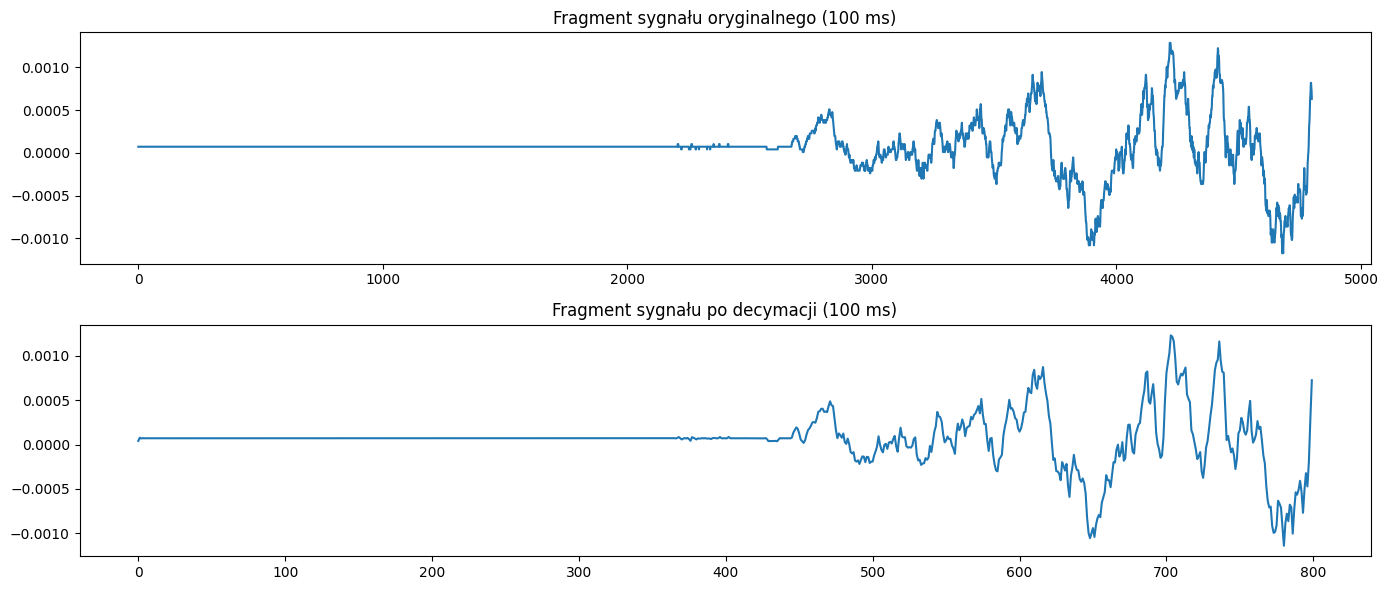

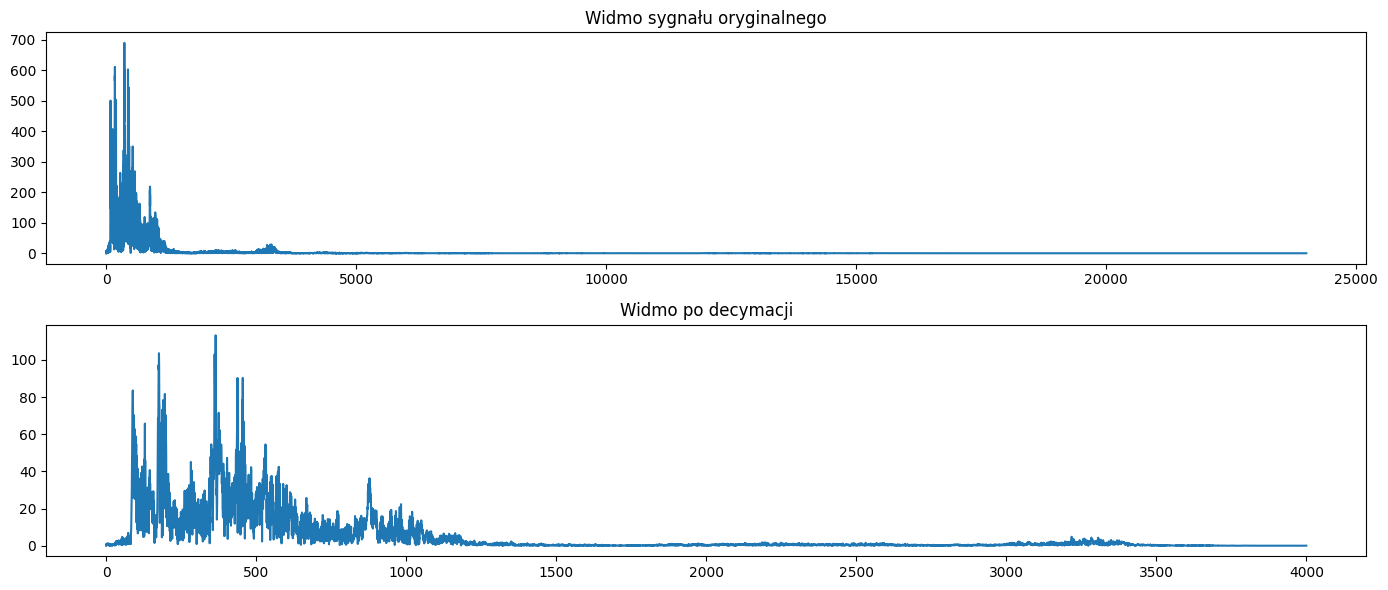

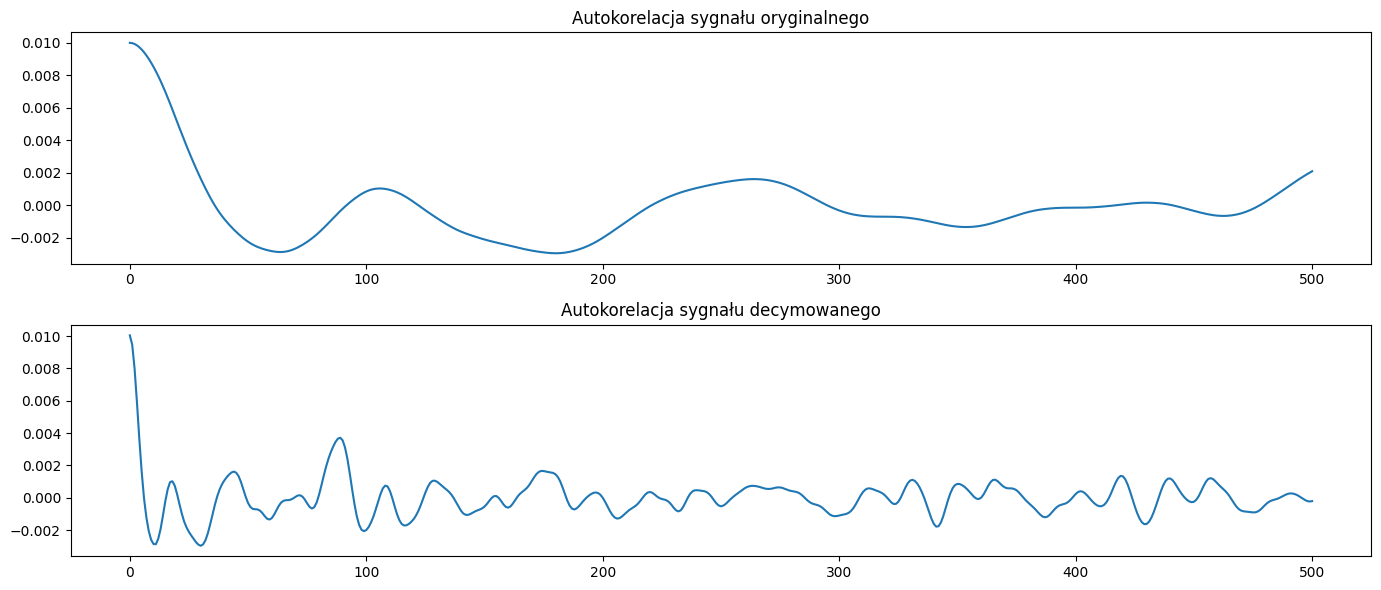

Oryginał:


Po decymacji:


In [ ]:
# usuń DC i normalizuj
x = remove_dc(x)
x = normalize_rms_to(0.1, x)

# resampling 48k -> 8k
y, fs_y = resample_decimate(x, fs, fs_out)

write_wav('JWPochmurnoDecimate.wav', fs_y, y)

# autokorelacje
r_x = autocorr(x, nlags=500)
r_y = autocorr(y, nlags=500)

# Wykresy czasowe
plt.figure(figsize=(14,6))
plt.subplot(2,1,1)
plt.title("Fragment sygnału oryginalnego (100 ms)")
plt.plot(x[:int(fs*0.1)])
plt.subplot(2,1,2)
plt.title("Fragment sygnału po decymacji (100 ms)")
plt.plot(y[:int(fs_out*0.1)])
plt.tight_layout()
plt.show()

# Widmo

X = np.abs(np.fft.rfft(x))
Y = np.abs(np.fft.rfft(y))

fX = np.linspace(0, fs/2, len(X))
fY = np.linspace(0, fs_out/2, len(Y))

plt.figure(figsize=(14,6))
plt.subplot(2,1,1)
plt.title("Widmo sygnału oryginalnego")
plt.plot(fX, X)
plt.subplot(2,1,2)
plt.title("Widmo po decymacji")
plt.plot(fY, Y)
plt.tight_layout()
plt.show()

# Autokorelacja – porównanie
plt.figure(figsize=(14,6))
plt.subplot(2,1,1)
plt.title("Autokorelacja sygnału oryginalnego")
plt.plot(r_x)

plt.subplot(2,1,2)
plt.title("Autokorelacja sygnału decymowanego")
plt.plot(r_y)
plt.tight_layout()
plt.show()

# odsłuch
print("Oryginał:")
display(Audio(x, rate=fs))

print("Po decymacji:")
display(Audio(y, rate=fs_y))

In [ ]:
def levinson_durbin(r, order):
    a = np.zeros(order + 1)
    a[0] = 1.0
    e = r[0]
    if e == 0:
        return np.zeros(order), 0.0
    for i in range(1, order + 1):
        acc = 0.0
        for j in range(1, i):
            acc += a[j] * r[i - j]
        k = -(r[i] + acc) / e
        a_prev = a.copy()
        a[i] = k
        for j in range(1, i):
            a[j] = a_prev[j] + k * a_prev[i - j]
        e *= (1.0 - k * k)
        if e <= 0:
            e = 1e-8
    return a[1:], e

In [ ]:
def frame_signal(x, fs, frame_ms=25, hop_ms=None, window_fn=np.hamming):
    if hop_ms is None:
        hop_ms = frame_ms / 2.0
    frame_len = int(round(frame_ms * fs / 1000.0))
    hop = int(round(hop_ms * fs / 1000.0))
    if frame_len <= 0:
        raise ValueError("frame_ms too small for sampling rate")
    # zero-pad na końcu
    n_frames = 1 + max(0, (len(x) - frame_len) // hop)

    total_len = (n_frames - 1) * hop + frame_len
    pad_len = max(0, total_len - len(x))
    x_padded = np.concatenate([x, np.zeros(pad_len)])
    frames = np.zeros((n_frames, frame_len))
    for i in range(n_frames):
        start = i * hop
        frames[i, :] = x_padded[start:start + frame_len]
    win = window_fn(frame_len)
    frames *= win
    return frames, frame_len, hop

In [ ]:
def detect_voiced(frame, fs, fmin=70, fmax=400):
    """
    Wykryj dźwięczność/bezdźwięczność na podstawie szczytu autokorelacji w zakresie fmin..fmax.
    Returns (voiced:bool, f0:float, r:autocorr array)
    """
    r = autocorr(frame, nlags=int(fs / fmin) + 5)
    lag_min = max(1, int(fs / fmax))
    lag_max = min(len(r) - 1, int(fs / fmin))
    if lag_min >= lag_max:
        return False, 0.0, r
    segment = r[lag_min:lag_max + 1]
    if len(segment) == 0:
        return False, 0.0, r
    peak_idx = np.argmax(segment)
    peak_val = segment[peak_idx]
    if r[0] <= 0:
        return False, 0.0, r
    voicing_ratio = peak_val / r[0]
    voiced = voicing_ratio > 0.28  # threshold (do zmiany)
    lag = lag_min + peak_idx
    f0 = fs / lag if lag > 0 else 0.0
    return bool(voiced), float(f0), r

In [ ]:
def generate_excitation(length, fs, f0, voiced, noise_gain=1.0):
    if voiced and f0 > 0:
        period = max(1, int(round(fs / f0)))
        exc = np.zeros(length)
        exc[::period] = 1.0
    else:
        exc = np.random.randn(length) * noise_gain
    return exc

def synthesize_from_lpc(frames_params, frame_len, hop, fs):
    n_frames = len(frames_params)
    out_len = (n_frames - 1) * hop + frame_len
    y = np.zeros(out_len)
    for i, prm in enumerate(frames_params):
        start = i * hop
        exc = generate_excitation(frame_len, fs, prm['f0'], prm['voiced'])
        a = np.concatenate(([1.0], prm['lpc']))
        g = np.sqrt(max(prm.get('gain', 1e-8), 1e-8))
        frame_out = signal.lfilter([g], a, exc)
        y[start:start + frame_len] += frame_out
    return y

In [ ]:
def analyze_and_synthesize(path_wav,
                           target_fs=8000,
                           lpc_order=10,
                           frame_ms=25,
                           hop_ms=None,
                           ref_rms=None,
                           filt_len=121,
                           plot=True):
    """
    Returns  'fs', 'original', 'synth', 'frames', 'params', 'frame_len', 'hop'
    """
    fs, x = read_wav(path_wav)
    print(f"Input: {path_wav}, fs={fs}, samples={len(x)}, duration={len(x)/fs:.2f}s")

    # 1. Resample
    x_res, fs_new = resample_decimate(x, fs, target_fs, filt_len=filt_len)
    print(f"Resampled to {fs_new} Hz, samples={len(x_res)}")

    # 2. Remove DC
    x_res = remove_dc(x_res)

    # 3. Normalize RMS
    if ref_rms is None:
        ref_rms = rms(x_res)
    x_res = normalize_rms_to(ref_rms, x_res)

    # 4. Framing & windowing
    frames, frame_len, hop = frame_signal(x_res, fs_new, frame_ms=frame_ms, hop_ms=hop_ms)
    n_frames = frames.shape[0]
    print(f"Frames: {n_frames}, frame_len={frame_len}, hop={hop}")

    # LPC i detekcja dźwięczności ramki
    frames_params = []
    for i in range(n_frames):
        fr = frames[i]
        r = autocorr(fr, nlags=lpc_order)
        lpc, err = levinson_durbin(r, lpc_order)
        voiced, f0, r_full = detect_voiced(fr, fs_new)
        frames_params.append({'lpc': lpc, 'gain': err, 'voiced': voiced, 'f0': f0})

    # 7. Synteza
    y = synthesize_from_lpc(frames_params, frame_len, hop, fs_new)
    # normalizacja wyjścia
    maxval = np.max(np.abs(y)) + 1e-16
    if maxval > 0:
        y = y / max(1.0, maxval)

    if plot:
        plot_waveforms(x_res, y, fs_new)
        plt.show()

    return {
        'fs': fs_new,
        'original': x_res,
        'synth': y,
        'frames': frames,
        'params': frames_params,
        'frame_len': frame_len,
        'hop': hop
    }

    #autpcpre;acka
    # ce[strum ]
    # wartpsc wyznaczamy eksperymentalnie
    # okolo 0.25 dla cepstrum
    # sprawdzenie nośnej i aproksymaty
    # harmoniczne szumu


In [ ]:
def plot_waveforms(orig, synth, fs, tmax=0.6):
    t_o = np.arange(len(orig)) / fs
    t_s = np.arange(len(synth)) / fs
    plt.figure(figsize=(10, 3.5))
    plt.plot(t_o, orig, label='Oryginał', alpha=0.8)
    plt.plot(t_s, synth, label='Synteza', alpha=0.7)
    plt.xlim(0, min(tmax, t_o[-1], t_s[-1]))
    plt.legend()
    plt.xlabel('Czas [s]')
    plt.ylabel('Amplituda')
    plt.title('Porównanie oryginału i syntezy (fragment)')
    plt.tight_layout()

def play_audio(arr, fs):
    display(Audio(arr, rate=fs))

In [ ]:
result = analyze_and_synthesize(path, target_fs=8000, lpc_order=10, frame_ms=25, plot=False)
play_audio(result['original'], result['fs'])
play_audio(result['synth'], result['fs'])
# Save
write_wav('JWPochmurnoSynth.wav', result['fs'], result['synth'])

Input: JWPochmurno.wav, fs=48000, samples=88064, duration=1.83s
Resampled to 8000 Hz, samples=14668
Frames: 145, frame_len=200, hop=100


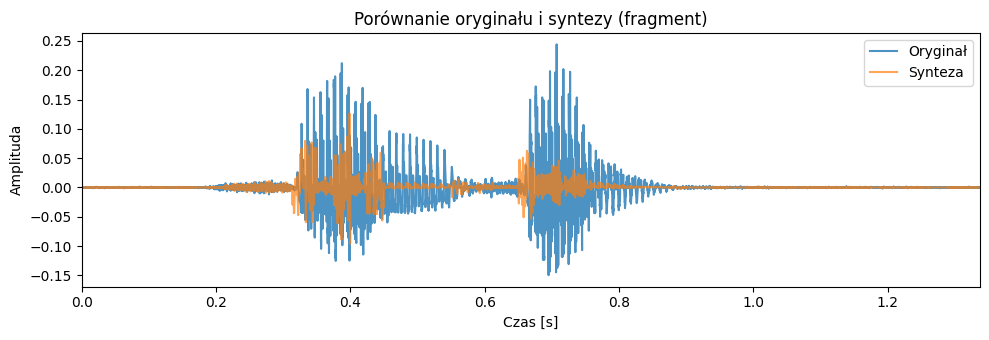

In [ ]:
plot_waveforms(result['original'], result['synth'], result['fs'],tmax=3)